# Total Spend: A Small PyTorch Neural Network
**Bakari Kerr**

This exploratory experiment tests a small multilayer perceptron (MLP) against the same total-spend split used for the tree models. The network predicts `log1p(total_spend)` and its predictions are converted to dollars for evaluation. Three predetermined seeds assess training variability; no architecture or hyperparameter search is performed.

An internal, fixed training-only holdout controls early stopping. The supplied newer-campaign validation set is used only after model fitting. This remains exploratory validation, not an untouched final H2 test. Results are produced by execution; improved performance over the trees is not assumed.


In [1]:
%pip install -q torch pandas numpy scikit-learn matplotlib


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Data and reproducibility

The loader uses `data/spend_train_val_split/` from the repository root or its `notebooks/` folder. Colab supports uploads of the same four CSVs, and `DATA_DIR` can reference mounted Google Drive.

The saved labels are raw total spend. The features are the team's pre-encoded planning candidates. Their availability at forecast time, especially campaign size and target-list size, has not been independently verified. Library versions and device are recorded. CPU execution keeps this small experiment simple and repeatable.


In [3]:
from pathlib import Path
import copy
import random
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torch import nn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from IPython.display import display

DATA_DIR = None  # Optional: Path('/content/drive/MyDrive/spend_train_val_split')
FILES = ['X_train.csv', 'X_val.csv', 'y_train.csv', 'y_val.csv']
if DATA_DIR is None:
    candidates = [Path.cwd() / 'data/spend_train_val_split',
                  Path.cwd().parent / 'data/spend_train_val_split', Path.cwd()]
    DATA_DIR = next((p for p in candidates if all((p / f).exists() for f in FILES)), None)
if DATA_DIR is None and 'google.colab' in sys.modules:
    from google.colab import files
    print('Upload the four spend split CSVs together (not the CPE split).')
    files.upload()
    DATA_DIR = Path.cwd()
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR to the folder containing the four spend split CSVs.')
DATA_DIR = Path(DATA_DIR)
missing = [f for f in FILES if not (DATA_DIR / f).exists()]
if missing:
    raise FileNotFoundError(f'Missing in {DATA_DIR}: {missing}')
X_train = pd.read_csv(DATA_DIR / 'X_train.csv')
X_val = pd.read_csv(DATA_DIR / 'X_val.csv')
y_train = pd.read_csv(DATA_DIR / 'y_train.csv')['total_spend']
y_val = pd.read_csv(DATA_DIR / 'y_val.csv')['total_spend']
assert len(X_train) == len(y_train) and len(X_val) == len(y_val)
assert X_train.columns.equals(X_val.columns) and X_train.columns.is_unique
for frame in [X_train, X_val]:
    assert all(pd.api.types.is_numeric_dtype(t) for t in frame.dtypes)
    assert np.isfinite(frame.to_numpy()).all()
for target in [y_train, y_val]:
    assert np.isfinite(target).all() and target.ge(0).all()
forbidden = {'total_spend', 'log_total_spend', 'actual_spend_per_engagement',
             'log_actual_spend_per_engagement', 'spend_per_NRx_lift', 'spend_near_zero'}
assert not (set(X_train) & forbidden)
DEVICE = torch.device('cpu')
torch.set_num_threads(1)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': True, 'grid.alpha': .2})
print(f'Training: {X_train.shape}; validation: {X_val.shape}')
print(f'PyTorch {torch.__version__}; numpy {np.__version__}; pandas {pd.__version__}; device: {DEVICE}')


Training: (332, 72); validation: (82, 72)
PyTorch 2.15.0+cpu; numpy 2.5.4; pandas 3.1.0; device: cpu


## 2. Internal stopping split and preprocessing

Twenty percent of the supplied training rows form an internal stopping set, fixed with seed 42 across network runs. The remaining rows fit weights. Actual dates are not retained in these CSVs, so this internal split is random rather than chronological; the external validation split remains the supplied older-versus-newer campaign split.

Input standardization and log-target standardization are fitted only on internal fitting rows. The stopping set selects the epoch with the lowest standardized log-target MSE. Standardizing the logged target improves numerical conditioning without changing the underlying squared-log-error objective.

The final models retain this internal split and are not refitted on all training rows. They therefore fit weights on fewer campaigns than the tree models, a limitation of this simple early-stopping comparison. Upstream category encoding had already used the full supplied training partition.


In [4]:
SEEDS = [42, 123, 2026]
STOP_SHARE = .20
fit_idx, stop_idx = train_test_split(np.arange(len(X_train)), test_size=STOP_SHARE, random_state=42)
x_scaler = StandardScaler().fit(X_train.iloc[fit_idx])
y_scaler = StandardScaler().fit(np.log1p(y_train.iloc[fit_idx]).to_numpy().reshape(-1, 1))

def x_tensor(frame):
    return torch.as_tensor(x_scaler.transform(frame), dtype=torch.float32, device=DEVICE)
def target_tensor(target):
    transformed = y_scaler.transform(np.log1p(np.asarray(target)).reshape(-1, 1))
    return torch.as_tensor(transformed, dtype=torch.float32, device=DEVICE)

X_fit_t = x_tensor(X_train.iloc[fit_idx])
X_stop_t = x_tensor(X_train.iloc[stop_idx])
y_fit_t = target_tensor(y_train.iloc[fit_idx])
y_stop_t = target_tensor(y_train.iloc[stop_idx])
print(f'Weight fitting: {len(fit_idx)}; internal stopping: {len(stop_idx)}; external validation: {len(y_val)}')
display(pd.DataFrame({'rows': [len(y_train), len(y_val)],
                      'MAPE eligible': [y_train.ge(1000).sum(), y_val.ge(1000).sum()],
                      'excluded from MAPE': [y_train.lt(1000).sum(), y_val.lt(1000).sum()]},
                     index=['supplied training', 'external validation']))


Weight fitting: 265; internal stopping: 67; external validation: 82


,rows,MAPE eligible,excluded from MAPE
supplied training,332,326,6
external validation,82,80,2


## 3. Fixed small network and training procedure

The MLP has one hidden layer of 16 ReLU units and one linear output. Adam uses learning rate 0.001 and weight decay 0.01. Mini-batches contain up to 32 rows. Training runs for at most 2,000 epochs, with patience 100 and minimum stopping-loss improvement 0.00001.

Each seed changes initialization and mini-batch order; the data partition, preprocessing, architecture, and optimizer settings remain fixed. The best internal stopping checkpoint is restored. No external validation labels enter training or early stopping. Learning-curve losses are standardized log-target MSE, not dollar errors or MAPE.


{'seed': 42, 'best_epoch': 16, 'epochs_run': 116, 'best_stop_MSE': 0.15959873795509338}
{'seed': 123, 'best_epoch': 26, 'epochs_run': 126, 'best_stop_MSE': 0.15420447289943695}
{'seed': 2026, 'best_epoch': 16, 'epochs_run': 116, 'best_stop_MSE': 0.1457221806049347}
Trainable parameters: 1185


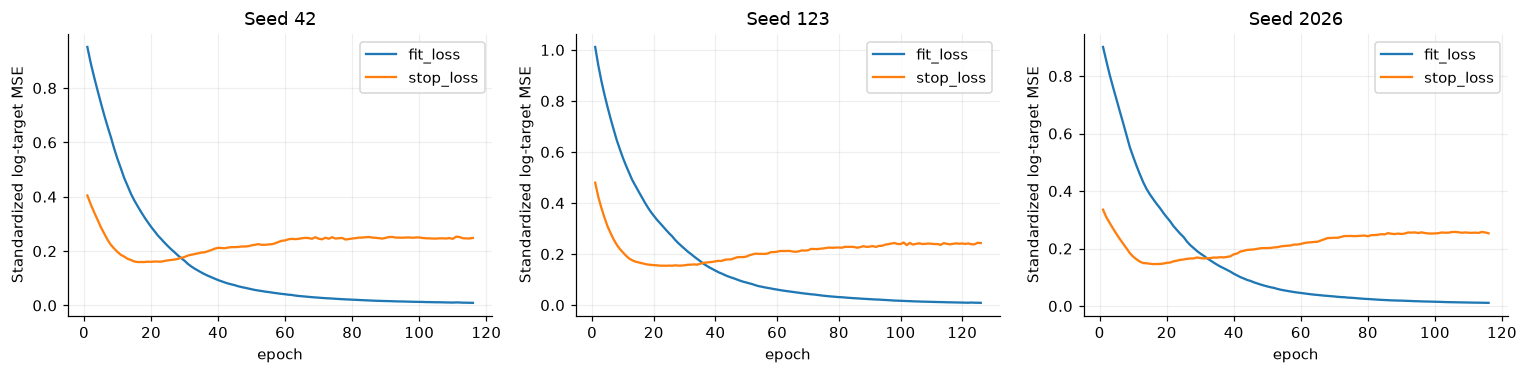

In [5]:
HIDDEN_UNITS = 16
LEARNING_RATE = .001
WEIGHT_DECAY = .01
BATCH_SIZE = 32
MAX_EPOCHS = 2000
PATIENCE = 100
MIN_DELTA = 1e-5

def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.use_deterministic_algorithms(True)

def make_model():
    return nn.Sequential(nn.Linear(X_train.shape[1], HIDDEN_UNITS), nn.ReLU(),
                         nn.Linear(HIDDEN_UNITS, 1)).to(DEVICE)

def train_one(seed):
    set_seed(seed)
    model = make_model()
    optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    loss_fn = nn.MSELoss()
    best_loss, best_epoch, stale = float('inf'), 0, 0
    best_state, history = None, []
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        order = torch.randperm(len(X_fit_t), device=DEVICE)
        for batch in order.split(BATCH_SIZE):
            optimizer.zero_grad(set_to_none=True)
            loss = loss_fn(model(X_fit_t[batch]), y_fit_t[batch])
            if not torch.isfinite(loss):
                raise RuntimeError(f'Nonfinite training loss for seed {seed}.')
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            fit_loss = loss_fn(model(X_fit_t), y_fit_t).item()
            stop_loss = loss_fn(model(X_stop_t), y_stop_t).item()
        if not np.isfinite([fit_loss, stop_loss]).all():
            raise RuntimeError(f'Nonfinite evaluation loss for seed {seed}.')
        history.append({'epoch': epoch, 'fit_loss': fit_loss, 'stop_loss': stop_loss})
        if stop_loss < best_loss - MIN_DELTA:
            best_loss, best_epoch, stale = stop_loss, epoch, 0
            best_state = copy.deepcopy(model.state_dict())
        else:
            stale += 1
        if stale >= PATIENCE:
            break
    assert best_state is not None
    model.load_state_dict(best_state)
    model.eval()
    return model, pd.DataFrame(history), {'seed': seed, 'best_epoch': best_epoch,
                                         'epochs_run': epoch, 'best_stop_MSE': best_loss}

models, histories, training_records = {}, {}, []
for seed in SEEDS:
    models[seed], histories[seed], record = train_one(seed)
    training_records.append(record)
    print(record)
print('Trainable parameters:', sum(p.numel() for p in models[SEEDS[0]].parameters()))
fig, axes = plt.subplots(1, len(SEEDS), figsize=(14, 3.5))
for ax, seed in zip(axes, SEEDS):
    histories[seed].plot(x='epoch', y=['fit_loss', 'stop_loss'], ax=ax)
    ax.set(title=f'Seed {seed}', ylabel='Standardized log-target MSE')
plt.tight_layout(); plt.show()


## 4. Dollar predictions and shared metrics

The standardized predictions are converted back to log spend and then dollars with `expm1`. Negative dollar predictions are clipped to zero, with the pre-clipping count reported. No log-to-dollar mean-bias correction is fitted; inverse transformation alone is not an unbiased estimate of conditional mean spend.

MAPE, median absolute percentage error, within-30%, typical factor off, and within-2x use actual spend of at least $1,000. Dollar MAE, RMSE, and R-squared include all rows. A zero prediction for eligible positive spend has infinite factor error. Median percentage error complements, rather than replaces, the project's MAPE metric.


In [6]:
def dollar_predictions(model, frame):
    model.eval()
    with torch.no_grad():
        standardized = model(x_tensor(frame)).cpu().numpy()
    log_pred = y_scaler.inverse_transform(standardized).ravel().astype(float)
    with np.errstate(over='raise', invalid='raise'):
        raw = np.expm1(log_pred)
    if not np.isfinite(raw).all():
        raise ValueError('Nonfinite dollar predictions; inspect the model.')
    return np.maximum(raw, 0), int((raw < 0).sum())

def metrics(actual, pred):
    a, p = np.asarray(actual, dtype=float), np.asarray(pred, dtype=float)
    assert a.shape == p.shape and np.isfinite(p).all() and (p >= 0).all()
    eligible = a >= 1000
    out = {'MAE ($)': mean_absolute_error(a, p), 'RMSE ($)': np.sqrt(mean_squared_error(a, p)),
           'R2': r2_score(a, p), 'log R2': r2_score(np.log1p(a), np.log1p(p)),
           'MAPE rows': int(eligible.sum())}
    names = ['MAPE (%)', 'median APE (%)', 'within 30% (%)', 'typical factor off', 'within 2x (%)']
    out.update({name: np.nan for name in names})
    if eligible.any():
        ae, pe = a[eligible], p[eligible]
        error = np.abs(ae - pe) / ae
        factor = np.full(len(ae), np.inf)
        positive = pe > 0
        factor[positive] = np.maximum(pe[positive] / ae[positive], ae[positive] / pe[positive])
        out.update(dict(zip(names, [100 * error.mean(), 100 * np.median(error),
                                   100 * np.mean(error <= .30), np.median(factor),
                                   100 * np.mean(factor <= 2)])))
    return out

predictions, rows, fitting_gaps = {}, [], []
for label, value in [('Training mean', y_train.mean()), ('Training median', y_train.median())]:
    rows.append({'experiment': label, **metrics(y_val, np.full(len(y_val), value))})
for seed, model in models.items():
    pred, negative = dollar_predictions(model, X_val)
    predictions[seed] = pred
    rows.append({'experiment': f'MLP seed {seed}', **metrics(y_val, pred),
                 'negative before clipping': negative})
    for split, frame, target in [('weight fitting', X_train.iloc[fit_idx], y_train.iloc[fit_idx]),
                                  ('internal stopping', X_train.iloc[stop_idx], y_train.iloc[stop_idx]),
                                  ('external validation', X_val, y_val)]:
        p, _ = dollar_predictions(model, frame)
        fitting_gaps.append({'seed': seed, 'split': split, **metrics(target, p)})
results_df = pd.DataFrame(rows).set_index('experiment')
display(results_df.round(4))
display(pd.DataFrame(fitting_gaps).round(4))
seed_metrics = results_df.loc[[f'MLP seed {seed}' for seed in SEEDS]]
display(seed_metrics[['MAPE (%)', 'median APE (%)', 'MAE ($)', 'R2']].agg(['mean', 'std', 'min', 'max']).round(4))
print('Seed standard deviations describe initialization variability, not statistical confidence intervals.')


,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),median APE (%),within 30% (%),typical factor off,within 2x (%),negative before clipping
experiment,,,,,,,,,,,
Training mean,1.471931e+09,1.679474e+09,-0.2779,-0.7435,80,6619.6183,1600.3845,5.00,17.0038,11.25,NaN
Training median,7.183268e+08,1.584433e+09,-0.1374,-0.0663,80,766.6825,105.2589,7.50,5.1306,16.25,NaN
MLP seed 42,5.914503e+08,1.452864e+09,0.0437,0.1660,80,180.1468,78.4101,21.25,2.6698,37.50,0.0
MLP seed 123,7.212560e+08,1.698459e+09,-0.3070,0.0659,80,240.3600,83.5293,25.00,3.5299,32.50,0.0
MLP seed 2026,6.344221e+08,1.422145e+09,0.0837,0.1709,80,222.0883,86.0746,15.00,3.0465,32.50,0.0


,seed,split,MAE ($),RMSE ($),R2,log R2,MAPE rows,MAPE (%),median APE (%),within 30% (%),typical factor off,within 2x (%)
0,42,weight fitting,1.247775e+09,4.510687e+09,0.0886,0.6347,259,127.2027,60.7161,25.8687,1.9739,50.9653
1,42,internal stopping,8.262284e+08,1.808949e+09,0.3841,0.6131,67,161.9325,72.3445,17.9104,2.5282,40.2985
2,42,external validation,5.914503e+08,1.452864e+09,0.0437,0.1660,80,180.1468,78.4101,21.2500,2.6698,37.5000
3,123,weight fitting,1.123952e+09,4.157216e+09,0.2258,0.7310,259,96.1696,48.8618,30.8880,1.7525,60.6178
4,123,internal stopping,9.078838e+08,1.955593e+09,0.2802,0.6262,67,137.1825,76.9417,14.9254,2.2147,38.8060
5,123,external validation,7.212560e+08,1.698459e+09,-0.3070,0.0659,80,240.3600,83.5293,25.0000,3.5299,32.5000
6,2026,weight fitting,1.202400e+09,4.406515e+09,0.1302,0.6287,259,109.0406,57.6582,27.0270,1.8858,54.4402
7,2026,internal stopping,8.403819e+08,1.715433e+09,0.4462,0.6468,67,154.4078,77.6268,11.9403,2.3292,40.2985
8,2026,external validation,6.344221e+08,1.422145e+09,0.0837,0.1709,80,222.0883,86.0746,15.0000,3.0465,32.5000


,MAPE (%),median APE (%),MAE ($),R2
mean,214.1983,82.6713,6.490428e+08,-0.0599
std,30.8722,3.9036,6.612641e+07,0.2149
min,180.1468,78.4101,5.914503e+08,-0.3070
max,240.3600,86.0746,7.212560e+08,0.0837


Seed standard deviations describe initialization variability, not statistical confidence intervals.


## 5. Diagnostics across seeds

Each seed is reported; no run is selected because it scores best on external validation. Error tables identify both large dollar mistakes and large percentage mistakes. Their CSV row numbers are not campaign identifiers. A high MAPE alongside much lower median percentage error indicates that large relative mistakes inflate the average, but does not make those mistakes irrelevant.


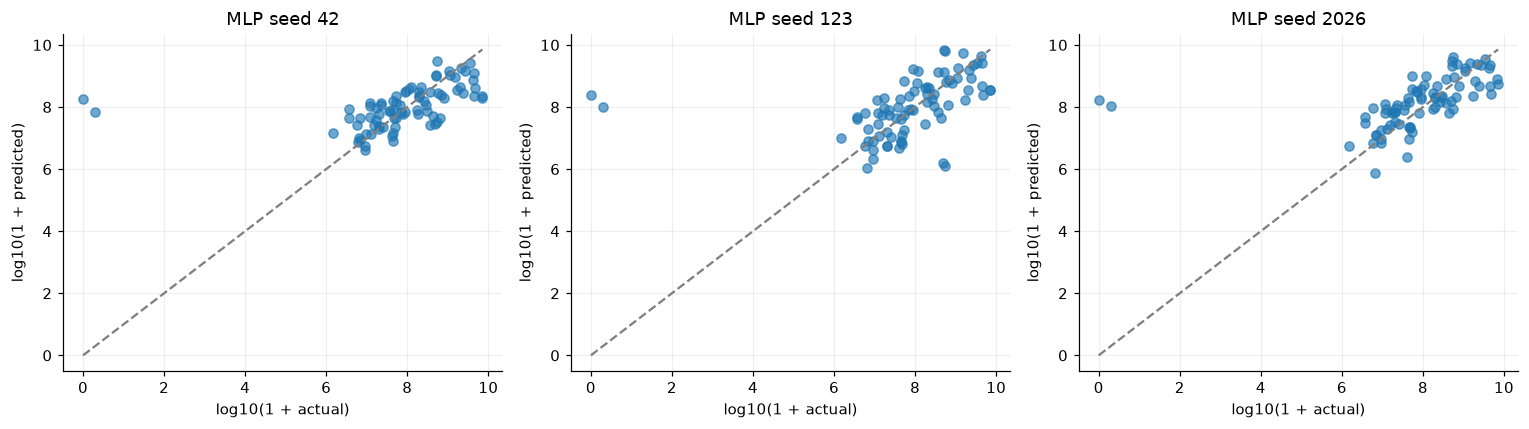

Seed 42: largest dollar mistakes


,validation_row,actual,predicted,absolute_error,APE (%)
3,3,7.130260e+09,2.006195e+08,6.929640e+09,97.186
48,48,6.898690e+09,2.234080e+08,6.675282e+09,96.762
46,46,4.559207e+09,2.211614e+08,4.338046e+09,95.149
28,28,4.724469e+09,4.104488e+08,4.314020e+09,91.312
61,61,4.233486e+09,7.584438e+08,3.475042e+09,82.085


Seed 42: largest percentage mistakes (eligible rows)


,validation_row,actual,predicted,absolute_error,APE (%)
26,26,3640000.0,8.483364e+07,8.119364e+07,2230.594
41,41,3704625.0,4.498130e+07,4.127668e+07,1114.193
34,34,11808000.0,1.300872e+08,1.182792e+08,1001.687
40,40,1500000.0,1.420768e+07,1.270768e+07,847.179
19,19,11904000.0,1.098049e+08,9.790087e+07,822.420


Top five percentage mistakes account for 41.7% of summed eligible percentage error.
Seed 123: largest dollar mistakes


,validation_row,actual,predicted,absolute_error,APE (%)
3,3,7.130260e+09,3.573926e+08,6.772867e+09,94.988
48,48,6.898690e+09,3.447943e+08,6.553895e+09,95.002
47,47,5.190420e+08,6.974972e+09,6.455930e+09,1243.816
36,36,5.524480e+08,6.291082e+09,5.738634e+09,1038.765
28,28,4.724469e+09,2.363154e+08,4.488154e+09,94.998


... (3 outputs left out)

,validation_row,actual,predicted,absolute_error,APE (%)
3,3,7.130260e+09,5.457357e+08,6.584524e+09,92.346
48,48,6.898690e+09,7.859972e+08,6.112693e+09,88.607
28,28,4.724469e+09,2.557509e+08,4.468718e+09,94.587
46,46,4.559207e+09,4.662016e+08,4.093005e+09,89.775
36,36,5.524480e+08,4.056702e+09,3.504254e+09,634.314


Seed 2026: largest percentage mistakes (eligible rows)


,validation_row,actual,predicted,absolute_error,APE (%)
23,23,54000000.0,1.025861e+09,9.718613e+08,1799.743
24,24,5820000.0,9.440727e+07,8.858727e+07,1522.118
41,41,3704625.0,4.598604e+07,4.228141e+07,1141.314
34,34,11808000.0,1.269686e+08,1.151606e+08,975.276
26,26,3640000.0,3.073625e+07,2.709625e+07,744.403


Top five percentage mistakes account for 34.8% of summed eligible percentage error.


In [7]:
fig, axes = plt.subplots(1, len(SEEDS), figsize=(14, 4))
diagnostics = {}
for ax, seed in zip(axes, SEEDS):
    pred = predictions[seed]
    actual_plot, pred_plot = np.log10(1 + y_val.to_numpy()), np.log10(1 + pred)
    ax.scatter(actual_plot, pred_plot, alpha=.65)
    lo, hi = min(actual_plot.min(), pred_plot.min()), max(actual_plot.max(), pred_plot.max())
    ax.plot([lo, hi], [lo, hi], '--', color='gray')
    ax.set(title=f'MLP seed {seed}', xlabel='log10(1 + actual)', ylabel='log10(1 + predicted)')
    d = pd.DataFrame({'validation_row': np.arange(len(y_val)), 'actual': y_val, 'predicted': pred})
    d['absolute_error'] = (d.actual - d.predicted).abs()
    d['APE (%)'] = np.nan
    eligible = d.actual.ge(1000)
    d.loc[eligible, 'APE (%)'] = 100 * d.loc[eligible, 'absolute_error'] / d.loc[eligible, 'actual']
    diagnostics[seed] = d
plt.tight_layout(); plt.show()
for seed, d in diagnostics.items():
    print(f'Seed {seed}: largest dollar mistakes')
    display(d.nlargest(5, 'absolute_error').round(3))
    print(f'Seed {seed}: largest percentage mistakes (eligible rows)')
    display(d.dropna(subset=['APE (%)']).nlargest(5, 'APE (%)').round(3))
    total = d['APE (%)'].sum()
    share = d['APE (%)'].nlargest(5).sum() / total if total > 0 else 0
    print(f'Top five percentage mistakes account for {share:.1%} of summed eligible percentage error.')


## 6. Comparison with the saved tree experiment

The reference numbers below are transcribed from the saved tree notebook run previously reviewed, not recomputed here. They are valid comparisons only when both notebooks use the same split contents. The tree models fitted weights on all 332 training campaigns, whereas the neural networks reserved an internal stopping set. This is an exploratory comparison of these training procedures, not a controlled test of maximum model capacity.

The reference logged Random Forest achieved MAPE 106.8491% and R-squared 0.5559; logged XGBoost achieved MAPE 124.6674% and R-squared 0.4207. Neither met the combined project targets. A neural-network advantage would need to be assessed across the predetermined seeds, rather than from its best seed alone. The existing validation set has already been inspected repeatedly and cannot provide independent final confirmation.


In [8]:
tree_reference = pd.DataFrame([
    {'experiment': 'Reference RF log', 'MAPE (%)': 106.8491, 'R2': .5559,
     'MAE ($)': 425649004., 'source': 'Previously saved tree run'},
    {'experiment': 'Reference XGBoost log', 'MAPE (%)': 124.6674, 'R2': .4207,
     'MAE ($)': 448639100., 'source': 'Previously saved tree run (MAE rounded)'}
]).set_index('experiment')
comparison = pd.concat([tree_reference, results_df.loc[[f'MLP seed {s}' for s in SEEDS],
                                                      ['MAPE (%)', 'R2', 'MAE ($)']]])
display(comparison.round(4))
print(f'MLP mean validation MAPE: {seed_metrics["MAPE (%)"].mean():.2f}%')
print(f'MLP mean validation R2: {seed_metrics["R2"].mean():.4f}')
print('Runs below 30% MAPE:', int(seed_metrics['MAPE (%)'].lt(30).sum()), '/', len(SEEDS))
print('Runs meeting both reference targets:',
      int((seed_metrics['MAPE (%)'].lt(30) & seed_metrics['R2'].gt(.55)).sum()), '/', len(SEEDS))
# Optional exports (disabled by default):
# results_df.to_csv('BakariKerr_TS_NN_Test_results.csv')
# pd.DataFrame(training_records).to_csv('BakariKerr_TS_NN_Test_training.csv', index=False)


,MAPE (%),R2,MAE ($),source
experiment,,,,
Reference RF log,106.8491,0.5559,4.256490e+08,Previously saved tree run
Reference XGBoost log,124.6674,0.4207,4.486391e+08,Previously saved tree run (MAE rounded)
MLP seed 42,180.1468,0.0437,5.914503e+08,NaN
MLP seed 123,240.3600,-0.3070,7.212560e+08,NaN
MLP seed 2026,222.0883,0.0837,6.344221e+08,NaN


MLP mean validation MAPE: 214.20%
MLP mean validation R2: -0.0599
Runs below 30% MAPE: 0 / 3
Runs meeting both reference targets: 0 / 3


## 7. Interpretation and scope

This experiment tests whether a small nonlinear neural network adds predictive value beyond fixed tree models with the available planning-candidate features. Its architecture, optimizer settings, seeds, and stopping procedure were fixed in advance. The model does not minimize MAPE directly, and low log-space loss need not imply accurate dollar predictions.

The reporting emphasizes all seeds, fitting/stopping curves, validation errors, and comparison with simple baselines. Large seed differences would suggest instability; similar errors across models could reflect missing information, distribution differences, or shared modeling limitations. Those explanations cannot be established from performance alone.

The sample is small, input categories were encoded upstream, and the internal stopping split is random. Prediction-time feature availability and an untouched H2 evaluation remain unverified. The recorded targets describe campaign spend, not ROI or causal advertising effectiveness. No model checkpoint or additional data file is written automatically.
